<a href="https://colab.research.google.com/github/c-lydia/operating_system/blob/main/robot_operating_system_2_basic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ROS 2: Robot Operating System 2

## What is ROS 2

ROS 2 (Robot Operating System 2) is an open source framework that allows you to develop robotic software application



## Running ROS 2 with Docker on WSL

Before running anything, you MUST open Docker Desktop first (not optional). Then, open Windows Powershell, in the Powershell, to run WSL, use this command:

``` ps1
wsl
```

After getting into WSL, change directory to `/home/<username>/kon-iot-dclab-docker-v2/` using this command:

``` bash
cd ~/kon-iot-dclab-docker
```

Then, run `dclab_docker` from that directory:

``` bash
./run-dclab-docker.sh
```

> In case, it output `Permission Denied`, allow execute permission with this command:

``` bash
chmod +x run-dclab-docker.sh
```

> Then, run `dclab_docker` again using the previous command

Once it's done, you should be in `~/ros2_ws`

To open another terminal inside container, you can use this command:

``` bash
docker exec -it <container_name> bash
```

You need to change `<container_name>` to your actual container name. If you don't know the name, you can run:

``` bash
docker ps
```

Then, note the value under `NAME` field, substitute that value into `<container_name>`

To get out of the container, run:

``` bash
exit
```

If you need further investigation about how certain docker command works, or if there's any issues with the command outputing errors, you can see the official documentation at [Docker Documentation](https://docs.docker.com/), and for WSL at [WSL Documentation](https://learn.microsoft.com/en-us/windows/wsl/)

## ROS 2 Concepts

### Configuring ROS 2 Environment

The ROS 2 environment needs to be correctly configured before being used.

#### Source the setup files

In every new terminal session, run this command

``` bash
source /opt/ros/jazzy/setup.bash
```

> `jazzy` can be replaced with other distro name if you use other distro. For example, if I'm running ROS 2 Lyrical (Ubuntu 26.04), I will replace `jazzy` with `lyrical`

``` bash
source /opt/ros/lyrical/setup.bash
```

**Optional:**

For those who don't want to run long command, you can add it to `~/.bashrc` using:

``` bash
echo "source /opt/ros/jazzy/setup.bash" >> ~/.bashrc
```

Then, in every terminal, you just reload `~/.bashrc`

``` bash
source ~/.bashrc
```

**Note:**

The `.bashrc` file is a shell script that the Bash shell runs whenever it starts interactively. In simple terms, every time you open a new terminal window, Bash reads and executes the commands inside this file. That makes it the ideal place for your personal Linux environment configuration.

It lets you store and automatically apply:

- **Command aliases:** Shortcuts for your most-used commands.
- **Shell functions:** More complex custom commands that can accept arguments.
- **Custom prompts:** Change the look and feel of your command prompt.
- **Environment variables:** Set paths and configurations for other programs.

#### `ROS_DOMAIN_ID`

If you have multiple ROS 2 nodes sending and receiving messages, how would you know it won't get confused over which to consume?

In ROS 2, nodes use Domain ID. ROS 2 nodes on the same domain can discover and send messages to each other, while ROS 2 nodes on different domains cannot.

To avoid interference between different groups of computers running ROS 2 on the same network, a different domain ID should be set for each group.

To set domain ID, you can use this command:

``` bash
export ROS_DOMAIN_ID=<your_domain_id>
```

Replace `<your_domain_id>` with your actual domain ID number (integer)

If you want this to persist between sessions, add it to `/bashrc`:

``` bash
echo "export ROS_DOMAIN_ID=<your_domain_id>" >> ~/.bashrc
```

### ROS 2 nodes



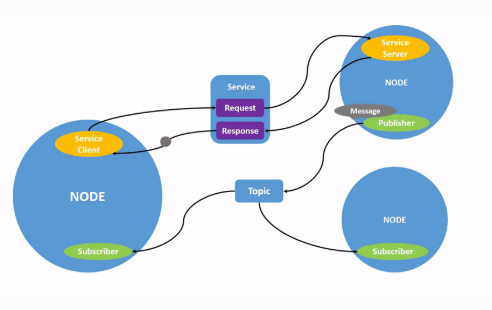

In [ ]:
from IPython.display import Image
Image('node.png')

In ROS 2, nodes are entities that is responsible for a single purpose; it can senf and receive data other nodes via topics, services, actions, or parameters.

#### `ros2 run`

`ros2 run` executes a node from a package

**Syntax:**

``` bash
ros2 run <package_name> <executable_name>
```

You need to replace `<package_name>` and `<executable_name>` by your actual package and executable.

**Example:** running turtlesim

``` bash
ros2 run turtlesim turtlesim_node
```

The turtlesim window will open.

the package here is `turtlesim` and executable is `turtlesim_node`.

To the the running node, run:

``` bash
ros2 node list
```

**Note:** the difference between node and executable is that node is the runtime entity (usually a process, which is technically a running program), and executable is the static code file on your computer (a `.py` script or compiles binary)

#### `ros2 node info`

To get information about a node, run:

``` bash
ros2 node info <node_name>
```

**Example:**

``` bash
ros2 node info /turtlsim_ndoe
```

## ROS 2 Topic

Topics can be thought of as the bus for the data to travel between nodes



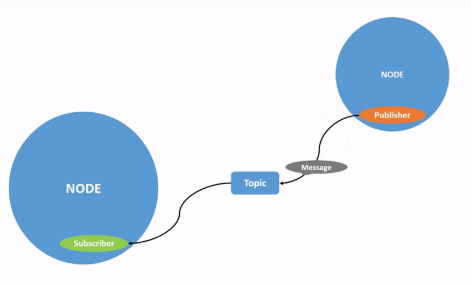

In [ ]:
from IPython.display import Image
Image('topic.png')

### `rqt_graph`

`rqt_graph` is used to visualize the running nodes and topics and the connections between them.

To see the graph, run:

``` bash
ros2 run rqt_graph rqt_graph
```

If you don't see anything, you can refresh the windows (at the left upper corner)

### `ros2 topic list`

`ros2 topic list` shows all the running topic

``` bash
ros2 topic list
```

To see the message type of each topic, use `-t`:

``` bash
ros2 topic list -t
```

### `ros2 topic echo`

Sometimes, you want to see data being published while debugging, so to see it, run:

``` bash
ros2 topic echo <topic_name>
```

**Example:**

``` bash
ros2 topic echo /turtle1/cmd_vel
```

Keep the terminal running, now, go to the terminal with `turtle_teleop_key` running, use the keyboard to control `turtle1`, and observe the data being sent on `ros2 topic echo`

### `ros2 topic info`

If you want to know information about a topic:

``` bash
ros2 topic info <topic_name>
```

**Example:**

``` bash
ros2 topic info /turtle1/cmd_vel
```

If you want to see more information:

``` bash
ros2 topic info <topic_name> --verbose
```

This returns:

- Node names and namespace of publishers and subscribers
- Topic type
- QoS profile

**Note:**

- **Namespace:** is a container that holds a set of identifiers or names, ensuring that they are unique to avoid any conflict
- **QoS (Quality of Service):** is a set of technologies and mechanisms on a network that guarantee its ability to dependebly run high-priority applications and traffic under limited network capacity, basically like a highway that allows critical data to flow first before the rest

### `ros2 interface show`

Interface is the type of data that gets sent over topic (message generally, or service for server-client, and action interface for action server-action client)

To see the message type of an interface, run:

``` bash
ros2 interface show <interface_name>
```

**Example:**

The topic `/turtle1/cmd_vel` publishes `geometry_msgs/msg/Twist` (check it with `ros2 topic info /turtle1/cmd_vel -t`)

If you want to see what fields are in the message, run:

``` bash
ros2 interface show gepmetry_msgs/msg/Twist
```

### `ros2 topic pub`

If you want to publish data, run:

``` bash
ros2 topic pub <topic_name> <msg_type> '<args>'
```

`<args>` is the data you'll publish

**Example:**

``` bash
ros2 topic pub /turtle1/cmd_vel geometry_msgs/msg/Twist "{linear: {x: 2.0, y: 0.0, z: 0.0}, angular: {x: 0.0, y: 0.0, z: 1.8}}"
```

This command will make the turtle moves in a circle

### `ros2 topic hz`

To view the rate of data incoming or outgoing:

``` bash
ros2 topic hz <topic_name>
```



## Launch

A real robot system has many nodes (can be up to 10+)

You don't want to open a new terminal everytime you need to run a node

Launch files allow you to start and configure a number of nodes at once

To run a launch file, use this:

``` bash
ros2 launch <package_name> <launch_file>
```

**Example:**

``` bash
ros2 launch turtlesim multisim.launch.py
```

This command will open two turtlesim windows

**Optional:**

You can control the turtle using `ros2 topic pub`

Open another terminal, then run:

``` bash
ros2 topic pub  /turtlesim1/turtle1/cmd_vel geometry_msgs/msg/Twist "{linear: {x: 2.0, y: 0.0, z: 0.0}, angular: {x: 0.0, y: 0.0, z: 1.8}}"
```

And, a third terminal:

``` bash
ros2 topic pub  /turtlesim2/turtle1/cmd_vel geometry_msgs/msg/Twist "{linear: {x: 2.0, y: 0.0, z: 0.0}, angular: {x: 0.0, y: 0.0, z: -1.8}}"
```

You should see both turtles moving in circle

## Demo: Simulation with Gazebo

Now, we will see how ROS 2 works in robot simulation

### Get into the container

Launch your container (`dclab_docker`)

Open WSL with powershell:

``` ps1
wsl
```

Inside WSL, run your container:

``` bash
cd ~/kon-iot-dclab-docker-v2
./run-dclab-docker.sh
```

### Prepare the packages

Extract the provided package and copy it into your WSL in another terminal

``` bash
cp /mnt/c/Users/<username?/Downloads/demo_bot-main.zip ~/
```

Or you can clone from this [demo_bot](https://github.com/c-lydia/demo_bot.git)

``` bash
git clone https://github.com/c-lydia/demo_bot.git
```

You should see the package when you run `ls`

### Build the packages

Get into `~/demo_bot`, then source ROS 2

``` bash
cd ~/demo_bot
source /opt/ros/jazzy/setup.bash
```

Then, build:

``` bash
colcon build
```

**Note:** the command `colcon build` build all the packages in the directories

### Run the launch file

Before running, install dependencies:

``` bash
sudo apt update
sudo apt upgrade
sudo apt install ros-jazzy-ros-gz ros-jazzy-joy   
```

Now, source the packages:

``` bash
source install/setup.bash
```

Then, run the launch file:

``` bash
ros2 launch demo_robot simulation.launch.py control_source:=keyboard
```

You should see a Gazebo windows, then open another terminal in the container, and run the control node:

``` bash
ros2 run demo_robot keyboard_pad
```

Now, you can use the keyboard to control the robot

## Resources

- [ROS 2 Documentation](https://docs.ros.org/en/jazzy/index.html)
- [Docker Documentation](https://docs.docker.com/)
- [WSL Documentation](https://learn.microsoft.com/en-us/windows/wsl/)
- [Gazebo Documentation](http://gazebosim.org/docs)
- [ROS 2 `rqt_graph` Tutorial](https://docs.ros.org/en/jazzy/Tutorials/Tools/Rqt-Graph/Rqt-Graph.html)
- [ROS 2 Launch System Documentation](https://docs.ros.org/en/jazzy/Tutorials/Launch-Files/Creating-a-Launch-File.html)
- [ROS 2 Quality of Service (QoS) Policies](https://docs.ros.org/en/jazzy/Concepts/About-Quality-of-Service-Settings.html)
- [ROS 2 Tutorials](https://docs.ros.org/en/jazzy/Tutorials.html)
- [ROS 2 Cheatsheet](https://docs.ros.org/en/jazzy/The-ROS2-Project/Contributing/ROS2-Code-Style-Guide.html) (While this is code style, it's a good general reference)
- [ROS 2 `colcon` Build Tool](https://colcon.readthedocs.io/en/released/)
- [Ubuntu Official Website](https://ubuntu.com/)
- [Dual Boot Windows and Ubuntu Guide](https://ubuntu.com/tutorials/install-ubuntu-desktop#1-download-and-prepare)